# Figure S1B — Myozenin-1 (Q9NP98): metapredict V1 disorder vs AF2 pLDDT

metapredict V1 disorder scores (top) and AlphaFold2 pLDDT (bottom) for Myozenin-1 (UniProt Q9NP98), which DisProt annotates as fully disordered (https://disprot.org/DP03529). Shaded residues are those each method calls disordered: V1 score ≥ 0.42 (the V1 threshold) or pLDDT ≤ 70 (AF2 low/very-low confidence). The two methods flag different regions, which motivated combining them in V2/V3.

**How it is made.** V1 scores are predicted live with metapredict; pLDDT values are read from `data/af2_plddt/Q9NP98_af2_plddt.tsv` in the shared data directory (AlphaFold DB model AF-Q9NP98-F1-model_v4).

**Output:** `figures/figure_S01B.pdf`

In [1]:
import metapredict as meta
import numpy as np

from disorder_vs_plddt import plot_disorder_vs_plddt
from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path

require_metapredict_3_1()
apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# AF2 pLDDT per residue; the sequence is reconstructed from the same file
plddt_table = np.genfromtxt(shared_data_path('af2_plddt', 'Q9NP98_af2_plddt.tsv'), delimiter='\t', names=True, dtype=None, encoding=None)
sequence = ''.join(plddt_table['amino_acid'])
plddt = plddt_table['plddt'].astype(float)

disorder = np.array(meta.predict_disorder(sequence, version='V1'))

Wrote figures/figure_S01B.pdf


PosixPath('figures/figure_S01B.pdf')

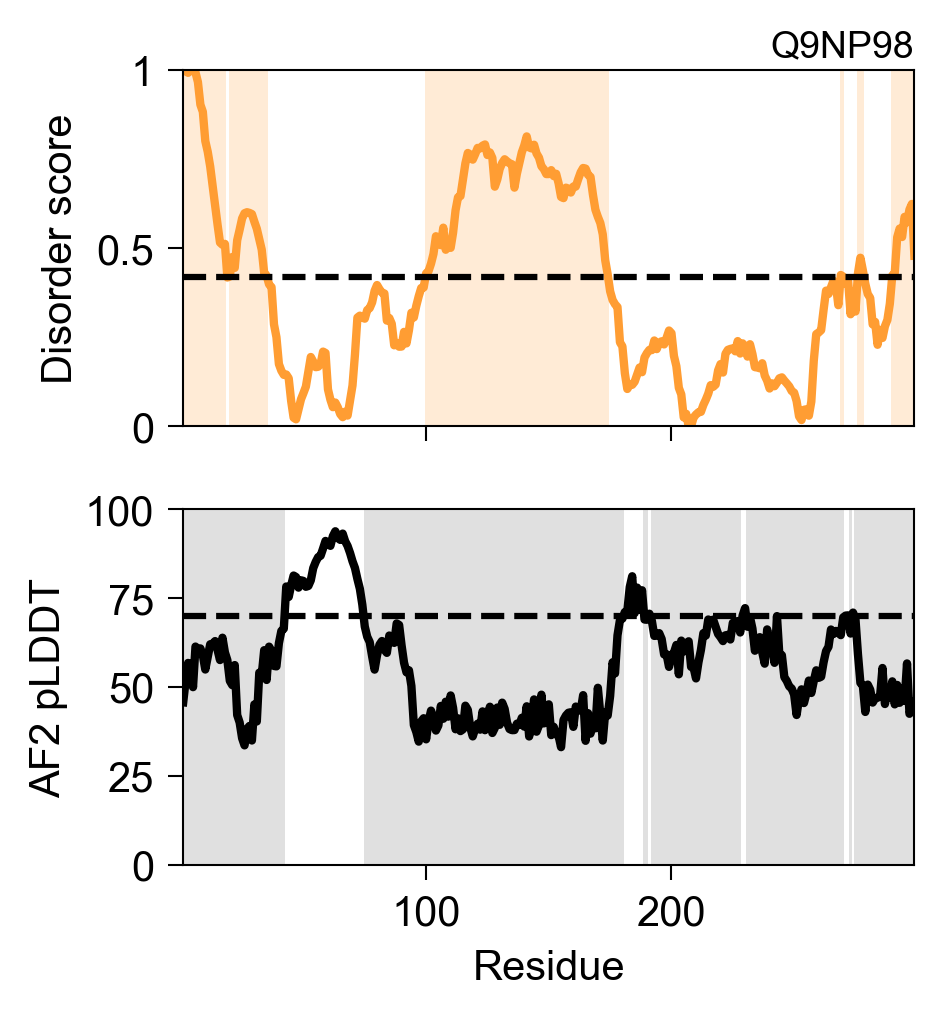

In [3]:
fig = plot_disorder_vs_plddt(disorder, plddt, label='Q9NP98')
save_panel(fig, 'figure_S01B')